# Problem 4.1: Continuous Autoencoder + VQ-VAE on CIFAR-10

| Model | Latent | Limit | Used for | Target |
|---|---|---|---|---|
| **Continuous autoencoder** | 5 × 8 × 8 = 320 real numbers | ≤ 8 × 8 × 5 | Transformer (4.3) | test PSNR > 25 dB |
| **VQ-VAE (discrete)** | 10 × 8 × 8 = 640 codebook indices (0..127) | ≤ 8 × 8 × 10 | discrete diffusion (4.2) | test PSNR > 25 dB |

**Continuous autoencoder:** convolutional encoder 3 × 32 × 32 → 5 × 8 × 8 real numbers → mirrored decoder, trained with MSE.

**VQ-VAE (van den Oord et al., 2017):**
1. The encoder turns an image into an 80 × 8 × 8 feature map = 10 groups of 8 numbers at each of the 8 × 8 positions.
2. **Vector quantization:** each 8-number vector is replaced by the **nearest vector in its group's codebook** (K = 128).
   The image is now 10 × 8 × 8 integers (the chosen codebook indices).
3. The decoder rebuilds the image from the quantized vectors.

VQ-VAE training tricks: straight-through estimator, commitment loss (β = 0.25), EMA codebook updates, dead-code restart.

**Already trained?** If `cae.pt` / `vqvae.pt` exist in the save folder (or a Kaggle input), they are **loaded instead of retrained**,
so earlier results (and the 4.3 latents) stay the same. Set `RETRAIN = True` to force training.

Works on **Colab** (saves to `MyDrive/mm811_p4_simple`) or **Kaggle** (saves to `/kaggle/working`). Use a GPU.

## 1. Settings and storage

In [4]:
import os, glob, math, time
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

RETRAIN = False      # True = train even if a saved model exists
CONT_CH = 5          # continuous latent 5 x 8 x 8
EPOCHS_CONT = 40
LR_CONT = 1e-3

GROUPS = 10          # VQ-VAE: codebooks per position -> latent 10 x 8 x 8
K = 128              # vectors per codebook
CODE_DIM = 8         # size of each codebook vector
BETA = 0.25          # commitment loss weight
EMA_DECAY = 0.99
BATCH_SIZE = 128
LR = 2e-4
EPOCHS = 15         # VQ-VAE epochs
print("device:", device)

ON_KAGGLE = os.path.exists("/kaggle")
if ON_KAGGLE:
    SAVE_DIR = "/kaggle/working"
else:
    from google.colab import drive
    drive.mount("/content/drive")
    SAVE_DIR = "/content/drive/MyDrive/mm811_p4_simple"
os.makedirs(SAVE_DIR, exist_ok=True)
print("saving to:", SAVE_DIR)

device: cuda
saving to: /kaggle/working


## 2. CIFAR-10
Uses `cifar10_uint8.pt` if you have it (saved by the 4.2 notebook; on Kaggle add it as an input), otherwise downloads CIFAR-10.

In [5]:
def find(name):
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True) if ON_KAGGLE else []
    for p in [f"{SAVE_DIR}/{name}"] + hits:
        if os.path.exists(p):
            return p
    return None

if ON_KAGGLE:      # copy any earlier results from Kaggle inputs into the working folder
    import shutil
    for name in ["cae.pt", "cae_latents.pt", "vqvae.pt", "vq_tokens.pt"]:
        p = find(name)
        if p and not os.path.exists(f"{SAVE_DIR}/{name}"):
            shutil.copy(p, SAVE_DIR); print("found", p)

cache = find("cifar10_uint8.pt")
if cache:
    cifar = torch.load(cache)
    print("loaded CIFAR-10 from", cache)
else:
    from torchvision import datasets
    tr = datasets.CIFAR10("./data", train=True, download=True)
    te = datasets.CIFAR10("./data", train=False, download=True)
    cifar = {"train_x": torch.from_numpy(tr.data).permute(0, 3, 1, 2).contiguous(), "train_y": torch.tensor(tr.targets),
             "test_x": torch.from_numpy(te.data).permute(0, 3, 1, 2).contiguous(), "test_y": torch.tensor(te.targets)}
    torch.save(cifar, f"{SAVE_DIR}/cifar10_uint8.pt")
    print("downloaded CIFAR-10 and saved cifar10_uint8.pt")

train_loader = DataLoader(TensorDataset(cifar["train_x"]), batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
test_loader = DataLoader(TensorDataset(cifar["test_x"]), batch_size=256)
to_float = lambda x: x.to(device).float().div(255)          # uint8 -> [0, 1]
print("train:", tuple(cifar["train_x"].shape), "| test:", tuple(cifar["test_x"].shape))

100%|██████████| 170M/170M [47:40<00:00, 59.6kB/s]


downloaded CIFAR-10 and saved cifar10_uint8.pt
train: (50000, 3, 32, 32) | test: (10000, 3, 32, 32)


## 3. Shared helpers

In [6]:
def psnr_batch(x, recon):
    mse = ((x - recon) ** 2).mean(dim=(1, 2, 3))
    return 10 * torch.log10(1 / mse)


def show_recon(x, recon, title, path):
    fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
    for i in range(8):
        axes[0, i].imshow(x[i].cpu().permute(1, 2, 0)); axes[0, i].axis("off")
        axes[1, i].imshow(recon[i].cpu().permute(1, 2, 0).clamp(0, 1)); axes[1, i].axis("off")
    axes[0, 0].set_title("Original", loc="left", fontsize=9); axes[1, 0].set_title(title, loc="left", fontsize=9)
    plt.tight_layout(); plt.savefig(path, dpi=120); plt.show()


def block(c_in, c_out):
    # 3x3 conv -> BatchNorm -> ReLU (keeps the size)
    return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU())

# Part A: Continuous autoencoder (latent 5 × 8 × 8)
Encoder 3 × 32 × 32 → 5 × 8 × 8 real numbers; decoder mirrors it. Trained with MSE, Adam, cosine learning rate.

In [7]:
class Autoencoder(nn.Module):
    def __init__(self, latent_ch, discrete=False):
        super().__init__()
        self.discrete = discrete
        self.encoder = nn.Sequential(
            block(3, 64),                                   # 64 x 32 x 32
            nn.Conv2d(64, 128, 4, stride=2, padding=1),     # 128 x 16 x 16
            nn.BatchNorm2d(128), nn.ReLU(),
            block(128, 128),
            nn.Conv2d(128, 256, 4, stride=2, padding=1),    # 256 x 8 x 8
            nn.BatchNorm2d(256), nn.ReLU(),
            block(256, 256),
            nn.Conv2d(256, latent_ch, 3, padding=1),        # latent: latent_ch x 8 x 8
        )
        self.decoder = nn.Sequential(
            block(latent_ch, 256),
            block(256, 256),
            nn.ConvTranspose2d(256, 128, 4, stride=2, padding=1),   # 128 x 16 x 16
            nn.BatchNorm2d(128), nn.ReLU(),
            block(128, 128),
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1),    # 64 x 32 x 32
            nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, 3, 3, padding=1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z


@torch.no_grad()
def cont_psnr(model, images_uint8):
    model.eval()
    total = 0.0
    for i in range(0, len(images_uint8), 500):
        x = to_float(images_uint8[i:i + 500])
        total += psnr_batch(x, model(x)[0]).sum().item()
    return total / len(images_uint8)


cae = Autoencoder(CONT_CH).to(device)
CAE_PATH = f"{SAVE_DIR}/cae.pt"
cont_hist = {"loss": [], "psnr": []}
if os.path.exists(CAE_PATH) and not RETRAIN:
    cae.load_state_dict(torch.load(CAE_PATH, map_location=device))
    print("loaded existing cae.pt (set RETRAIN = True to train again)")
else:
    opt = torch.optim.Adam(cae.parameters(), lr=LR_CONT)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS_CONT)
    for epoch in range(1, EPOCHS_CONT + 1):
        cae.train()
        running, t0 = 0.0, time.time()
        for (x,) in train_loader:
            x = to_float(x)
            loss = F.mse_loss(cae(x)[0], x)
            opt.zero_grad(); loss.backward(); opt.step()
            running += loss.item()
        sched.step()
        cont_hist["loss"].append(running / len(train_loader))
        cont_hist["psnr"].append(cont_psnr(cae, cifar["test_x"]))
        print(f"[Continuous] Epoch {epoch:2d} | loss {cont_hist['loss'][-1]:.5f} | test PSNR {cont_hist['psnr'][-1]:.2f} dB "
              f"| {time.time() - t0:.0f}s")
    torch.save(cae.state_dict(), CAE_PATH)

[Continuous] Epoch  1 | loss 0.00821 | test PSNR 25.26 dB | 34s
[Continuous] Epoch  2 | loss 0.00300 | test PSNR 26.24 dB | 32s
[Continuous] Epoch  3 | loss 0.00263 | test PSNR 26.28 dB | 33s
[Continuous] Epoch  4 | loss 0.00238 | test PSNR 26.86 dB | 34s
[Continuous] Epoch  5 | loss 0.00233 | test PSNR 26.09 dB | 34s
[Continuous] Epoch  6 | loss 0.00220 | test PSNR 26.86 dB | 35s
[Continuous] Epoch  7 | loss 0.00215 | test PSNR 26.42 dB | 35s
[Continuous] Epoch  8 | loss 0.00207 | test PSNR 27.82 dB | 35s
[Continuous] Epoch  9 | loss 0.00201 | test PSNR 27.40 dB | 36s
[Continuous] Epoch 10 | loss 0.00200 | test PSNR 27.91 dB | 36s
[Continuous] Epoch 11 | loss 0.00198 | test PSNR 27.81 dB | 36s
[Continuous] Epoch 12 | loss 0.00194 | test PSNR 26.68 dB | 36s
[Continuous] Epoch 13 | loss 0.00187 | test PSNR 28.12 dB | 36s
[Continuous] Epoch 14 | loss 0.00187 | test PSNR 26.57 dB | 36s
[Continuous] Epoch 15 | loss 0.00182 | test PSNR 28.03 dB | 36s
[Continuous] Epoch 16 | loss 0.00179 | t

Continuous autoencoder | train PSNR 29.38 dB | test PSNR 29.19 dB -> target > 25 dB: MET


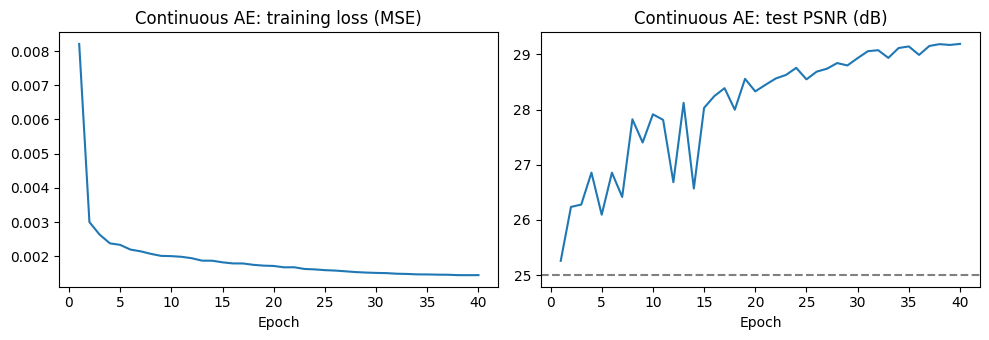

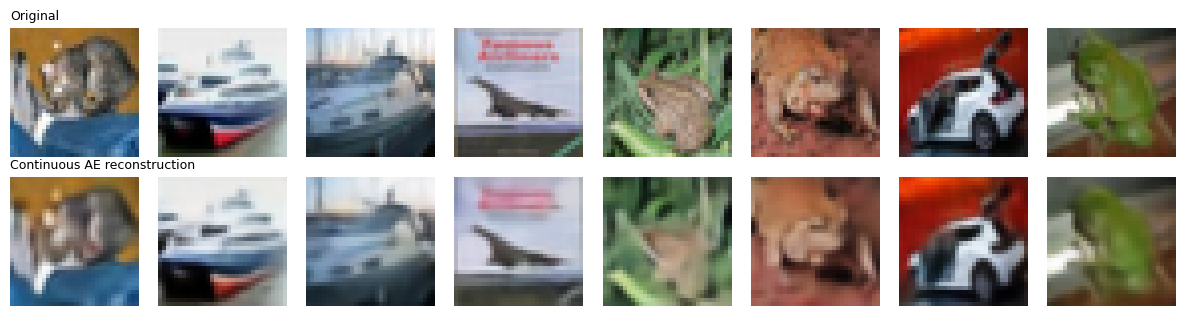

saved cae_latents.pt | train (50000, 5, 8, 8) | test (10000, 5, 8, 8) | mean -0.086 | std 6.034


In [8]:
cont_train = cont_psnr(cae, cifar["train_x"])
cont_test = cont_psnr(cae, cifar["test_x"])
print(f"Continuous autoencoder | train PSNR {cont_train:.2f} dB | test PSNR {cont_test:.2f} dB "
      f"-> target > 25 dB: {'MET' if cont_test > 25 else 'NOT MET'}")

if cont_hist["loss"]:
    ep = range(1, len(cont_hist["loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    ax[0].plot(ep, cont_hist["loss"]); ax[0].set_title("Continuous AE: training loss (MSE)"); ax[0].set_xlabel("Epoch")
    ax[1].plot(ep, cont_hist["psnr"]); ax[1].axhline(25, color="gray", linestyle="--")
    ax[1].set_title("Continuous AE: test PSNR (dB)"); ax[1].set_xlabel("Epoch")
    plt.tight_layout(); plt.savefig(f"{SAVE_DIR}/cae_curves.png", dpi=120); plt.show()

cae.eval()
x = to_float(cifar["test_x"][:8])
with torch.no_grad():
    show_recon(x, cae(x)[0], "Continuous AE reconstruction", f"{SAVE_DIR}/cae_reconstructions.png")

# Save the continuous latents for the Transformer (4.3)
LAT_PATH = f"{SAVE_DIR}/cae_latents.pt"
if os.path.exists(LAT_PATH) and not RETRAIN and not cont_hist["loss"]:
    print("kept existing cae_latents.pt")
else:
    with torch.no_grad():
        enc = lambda imgs: torch.cat([cae.encoder(to_float(imgs[i:i + 500])).cpu() for i in range(0, len(imgs), 500)])
        latents = {"train": enc(cifar["train_x"]), "test": enc(cifar["test_x"])}
    latents["mean"], latents["std"] = latents["train"].mean(), latents["train"].std()
    torch.save(latents, LAT_PATH)
    print("saved cae_latents.pt | train", tuple(latents["train"].shape), "| test", tuple(latents["test"].shape),
          f"| mean {latents['mean']:.3f} | std {latents['std']:.3f}")

# Part B: VQ-VAE (latent 10 × 8 × 8 codebook indices)

## B1. Vector quantizer (10 codebooks, EMA updates, dead-code restart)
Input: encoder output of shape (B, 10·8, 8, 8). For each of the 10 groups and each of the 8 × 8 positions,
find the nearest of the K = 128 codebook vectors (Euclidean distance) and replace the vector by it.

In [9]:
class GroupedVQ(nn.Module):
    def __init__(self, groups, k, dim, decay=0.99, eps=1e-5):
        super().__init__()
        self.G, self.K, self.d, self.decay, self.eps = groups, k, dim, decay, eps
        self.register_buffer("embed", torch.randn(groups, k, dim))         # the codebooks
        self.register_buffer("embed_avg", self.embed.clone())
        self.register_buffer("cluster_size", torch.ones(groups, k))
        self.register_buffer("initted", torch.tensor(False))

    def forward(self, z):
        B, _, H, W = z.shape
        z = z.float().view(B, self.G, self.d, H, W).permute(1, 0, 3, 4, 2).reshape(self.G, -1, self.d)  # (G, N, d)

        if self.training and not self.initted:          # start the codebooks from real encoder outputs
            for g in range(self.G):
                self.embed[g] = z[g][torch.randint(0, z.shape[1], (self.K,), device=z.device)]
            self.embed_avg.copy_(self.embed)
            self.initted.fill_(True)

        dist = (z ** 2).sum(-1, keepdim=True) - 2 * z @ self.embed.transpose(1, 2) + (self.embed ** 2).sum(-1)[:, None]
        idx = dist.argmin(-1)                                                # (G, N) nearest code
        q = torch.gather(self.embed, 1, idx[..., None].expand(-1, -1, self.d))   # (G, N, d)

        if self.training:
            with torch.no_grad():
                onehot = F.one_hot(idx, self.K).float()                       # (G, N, K)
                self.cluster_size.mul_(self.decay).add_(onehot.sum(1), alpha=1 - self.decay)
                self.embed_avg.mul_(self.decay).add_(onehot.transpose(1, 2) @ z, alpha=1 - self.decay)
                n = self.cluster_size.sum(-1, keepdim=True)
                size = (self.cluster_size + self.eps) / (n + self.K * self.eps) * n
                self.embed.copy_(self.embed_avg / size[..., None])
                dead = self.cluster_size < 1.0                                # codes nobody has used lately
                for g in range(self.G):
                    nd = int(dead[g].sum())
                    if nd:
                        new = z[g][torch.randint(0, z.shape[1], (nd,), device=z.device)]
                        self.embed[g, dead[g]] = new
                        self.embed_avg[g, dead[g]] = new
                        self.cluster_size[g, dead[g]] = 1.0

        commit = F.mse_loss(z, q.detach())
        q = z + (q - z).detach()                                             # straight-through estimator
        q = q.view(self.G, B, H, W, self.d).permute(1, 0, 4, 2, 3).reshape(B, self.G * self.d, H, W)
        idx = idx.view(self.G, B, H, W).permute(1, 0, 2, 3)                  # (B, 10, 8, 8) integers 0..K-1
        return q, idx, commit

    def lookup(self, idx):
        # integer indices (B, 10, 8, 8) -> quantized vectors (B, 80, 8, 8), for decoding generated tokens
        B, G, H, W = idx.shape
        q = torch.stack([self.embed[g][idx[:, g]] for g in range(G)], 1)     # (B, G, H, W, d)
        return q.permute(0, 1, 4, 2, 3).reshape(B, G * self.d, H, W)

## B2. VQ-VAE encoder and decoder
Same convolutional design as the continuous autoencoder, plus residual blocks, with an 80-channel latent (10 groups × 8).

In [10]:
class ResBlock(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.net = nn.Sequential(nn.ReLU(), nn.Conv2d(c, c, 3, padding=1), nn.BatchNorm2d(c),
                                 nn.ReLU(), nn.Conv2d(c, c, 1), nn.BatchNorm2d(c))

    def forward(self, x):
        return x + self.net(x)


class VQVAE(nn.Module):
    def __init__(self):
        super().__init__()
        latent = GROUPS * CODE_DIM
        self.encoder = nn.Sequential(
            block(3, 64),                                                     # 64 x 32 x 32
            nn.Conv2d(64, 128, 4, stride=2, padding=1), nn.BatchNorm2d(128), nn.ReLU(),   # 16 x 16
            block(128, 128),
            nn.Conv2d(128, 256, 4, stride=2, padding=1), nn.BatchNorm2d(256), nn.ReLU(),  # 8 x 8
            ResBlock(256), ResBlock(256), nn.ReLU(),
            nn.Conv2d(256, latent, 1),                                        # 80 x 8 x 8
        )
        self.vq = GroupedVQ(GROUPS, K, CODE_DIM, decay=EMA_DECAY)
        self.decoder = nn.Sequential(
            nn.Conv2d(latent, 256, 3, padding=1), nn.BatchNorm2d(256),
            ResBlock(256), ResBlock(256), nn.ReLU(),
            nn.ConvTranspose2d(256, 128, 4, stride=2, padding=1), nn.BatchNorm2d(128), nn.ReLU(),  # 16 x 16
            block(128, 128),
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1), nn.BatchNorm2d(64), nn.ReLU(),    # 32 x 32
            nn.Conv2d(64, 3, 3, padding=1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        q, idx, commit = self.vq(self.encoder(x))
        return self.decoder(q), idx, commit

    @torch.no_grad()
    def decode_tokens(self, idx):
        return self.decoder(self.vq.lookup(idx.to(self.vq.embed.device)))


model = VQVAE().to(device)
with torch.no_grad():
    model.eval(); _, idx, _ = model(torch.zeros(2, 3, 32, 32, device=device)); model.train()
print("parameters:", sum(p.numel() for p in model.parameters()), "| latent:", tuple(idx.shape[1:]),
      "=", idx[0].numel(), "integers in 0 ..", K - 1)

parameters: 4445011 | latent: (10, 8, 8) = 640 integers in 0 .. 127


## B3. VQ-VAE training

In [11]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    psnr, n, counts = 0.0, 0, torch.zeros(GROUPS, K)
    for (x,) in loader:
        x = to_float(x)
        recon, idx, _ = model(x)
        mse = ((x - recon) ** 2).mean(dim=(1, 2, 3))
        psnr += (10 * torch.log10(1 / mse)).sum().item(); n += len(x)
        for g in range(GROUPS):
            counts[g] += torch.bincount(idx[:, g].flatten().cpu(), minlength=K)
    p = counts / counts.sum(1, keepdim=True)
    perplexity = torch.exp(-(p * torch.log(p + 1e-10)).sum(1)).mean().item()   # effective number of codes used
    used = (counts > 0).float().sum(1).mean().item()
    return psnr / n, perplexity, used


history = {"loss": [], "psnr": [], "perplexity": []}
VQ_PATH = f"{SAVE_DIR}/vqvae.pt"
if os.path.exists(VQ_PATH) and not RETRAIN:
    model.load_state_dict(torch.load(VQ_PATH, map_location=device))
    print("loaded existing vqvae.pt (set RETRAIN = True to train again)")
    train_epochs = []
else:
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    train_epochs = range(1, EPOCHS + 1)

for epoch in train_epochs:
    model.train()
    running, t0 = 0.0, time.time()
    for (x,) in train_loader:
        x = to_float(x)
        x = torch.where(torch.rand(len(x), 1, 1, 1, device=device) < 0.5, x.flip(-1), x)   # random horizontal flip
        recon, _, commit = model(x)
        loss = F.mse_loss(recon, x) + BETA * commit
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running += loss.item()
    scheduler.step()
    psnr, perp, used = evaluate(model, test_loader)
    history["loss"].append(running / len(train_loader)); history["psnr"].append(psnr); history["perplexity"].append(perp)
    print(f"Epoch {epoch:2d} | loss {history['loss'][-1]:.5f} | test PSNR {psnr:.2f} dB | "
          f"codes used {used:.0f}/{K} | perplexity {perp:.1f} | {time.time() - t0:.0f}s")

if history["loss"]:
    torch.save(model.state_dict(), VQ_PATH)

Epoch  1 | loss 0.00920 | test PSNR 24.37 dB | codes used 126/128 | perplexity 85.8 | 45s
Epoch  2 | loss 0.00325 | test PSNR 26.55 dB | codes used 128/128 | perplexity 96.0 | 45s
Epoch  3 | loss 0.00237 | test PSNR 28.45 dB | codes used 128/128 | perplexity 104.0 | 45s
Epoch  4 | loss 0.00184 | test PSNR 27.80 dB | codes used 128/128 | perplexity 105.1 | 45s
Epoch  5 | loss 0.00157 | test PSNR 27.62 dB | codes used 128/128 | perplexity 105.0 | 45s
Epoch  6 | loss 0.00145 | test PSNR 29.75 dB | codes used 128/128 | perplexity 106.6 | 45s
Epoch  7 | loss 0.00132 | test PSNR 30.71 dB | codes used 128/128 | perplexity 106.4 | 45s
Epoch  8 | loss 0.00118 | test PSNR 31.02 dB | codes used 128/128 | perplexity 105.7 | 45s
Epoch  9 | loss 0.00109 | test PSNR 30.31 dB | codes used 128/128 | perplexity 107.2 | 45s
Epoch 10 | loss 0.00104 | test PSNR 31.81 dB | codes used 128/128 | perplexity 106.4 | 45s
Epoch 11 | loss 0.00099 | test PSNR 31.70 dB | codes used 128/128 | perplexity 107.2 | 45s
E

## B4. VQ-VAE results

Train PSNR: 32.49 dB
Test PSNR:  32.47 dB  -> target > 25 dB: MET
Latent: 10 x 8 x 8 = 640 indices (limit 8 x 8 x 10) | codebook usage 128/128, perplexity 105.4


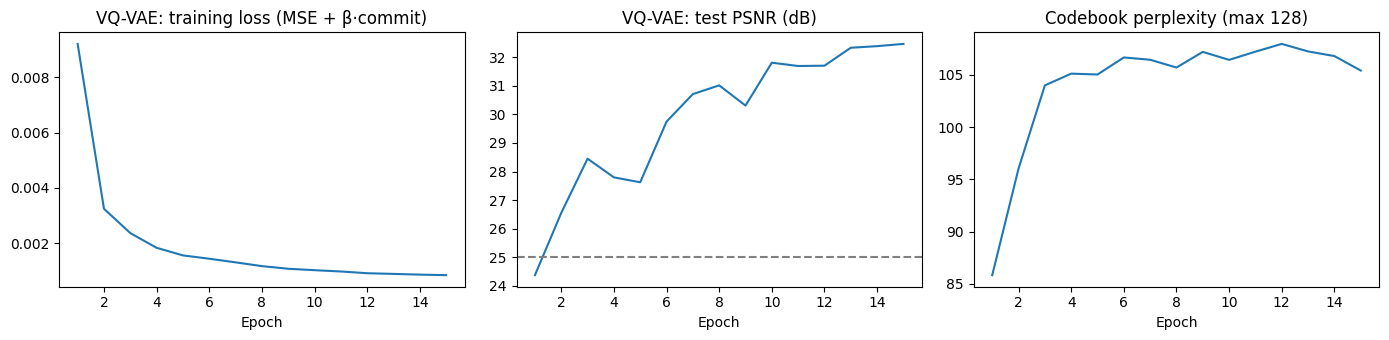

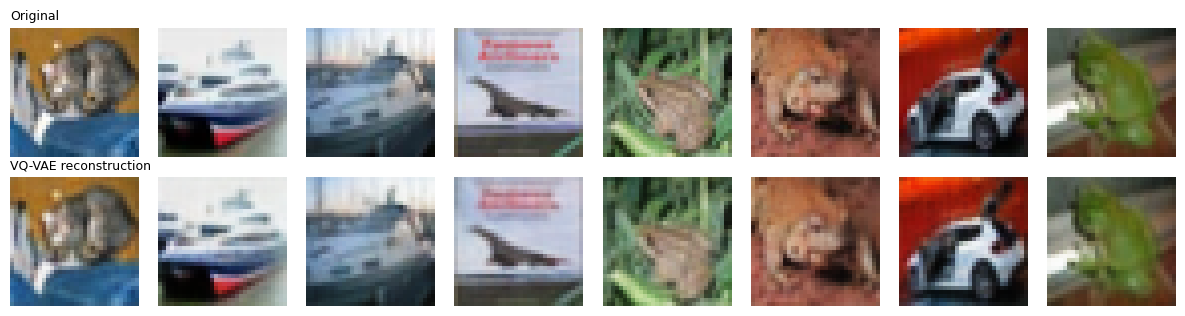

In [12]:
train_psnr, _, _ = evaluate(model, DataLoader(TensorDataset(cifar["train_x"]), batch_size=256))
test_psnr, perp, used = evaluate(model, test_loader)
print(f"Train PSNR: {train_psnr:.2f} dB")
print(f"Test PSNR:  {test_psnr:.2f} dB  -> target > 25 dB:", "MET" if test_psnr > 25 else "NOT MET")
print(f"Latent: {GROUPS} x 8 x 8 = {GROUPS * 64} indices (limit 8 x 8 x 10) | codebook usage {used:.0f}/{K}, perplexity {perp:.1f}")

ep = range(1, len(history["loss"]) + 1)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5)) if history["loss"] else (None, None)
if history["loss"]:
    ax[0].plot(ep, history["loss"]); ax[0].set_title("VQ-VAE: training loss (MSE + β·commit)"); ax[0].set_xlabel("Epoch")
    ax[1].plot(ep, history["psnr"]); ax[1].axhline(25, color="gray", linestyle="--"); ax[1].set_title("VQ-VAE: test PSNR (dB)"); ax[1].set_xlabel("Epoch")
    ax[2].plot(ep, history["perplexity"]); ax[2].set_title(f"Codebook perplexity (max {K})"); ax[2].set_xlabel("Epoch")
    plt.tight_layout(); plt.savefig(f"{SAVE_DIR}/vqvae_curves.png", dpi=120); plt.show()

model.eval()
x = to_float(cifar["test_x"][:8])
with torch.no_grad():
    recon, _, _ = model(x)
show_recon(x, recon, "VQ-VAE reconstruction", f"{SAVE_DIR}/vqvae_reconstructions.png")

## B5. Save the VQ tokens (for 4.2)
Each image becomes 10 × 8 × 8 codebook indices in 0..127. Saved as `vq_tokens.pt`, in the same order as CIFAR-10.
`model.decode_tokens(idx)` turns indices back into images.

In [13]:
@torch.no_grad()
def get_tokens(images_uint8):
    model.eval()
    return torch.cat([model(to_float(images_uint8[i:i + 500]))[1].to(torch.uint8).cpu()
                      for i in range(0, len(images_uint8), 500)])

vq_tokens = {"train": get_tokens(cifar["train_x"]), "test": get_tokens(cifar["test_x"]), "codebook_size": K}
torch.save(vq_tokens, f"{SAVE_DIR}/vq_tokens.pt")

check = model.decode_tokens(vq_tokens["test"][:8].long())                     # decoding from saved indices
print("tokens train:", tuple(vq_tokens["train"].shape), "| test:", tuple(vq_tokens["test"].shape))
print("decode-from-tokens matches reconstruction:", torch.allclose(check, recon, atol=1e-5))
print("saved:", sorted(f for f in os.listdir(SAVE_DIR) if f.startswith("vq")))

tokens train: (50000, 10, 8, 8) | test: (10000, 10, 8, 8)
decode-from-tokens matches reconstruction: True
saved: ['vq_tokens.pt', 'vqvae.pt', 'vqvae_curves.png', 'vqvae_reconstructions.png']


# Summary

In [14]:
vq_train, vq_test = train_psnr, test_psnr
print(f"{'Model':<14}{'Latent':<32}{'Train PSNR':>12}{'Test PSNR':>12}{'> 25 dB':>10}")
print(f"{'Continuous':<14}{'5x8x8 = 320 real numbers':<32}{cont_train:>10.2f}dB{cont_test:>10.2f}dB{'MET' if cont_test > 25 else 'NOT MET':>10}")
print(f"{'VQ-VAE':<14}{'10x8x8 = 640 indices (K=128)':<32}{vq_train:>10.2f}dB{vq_test:>10.2f}dB{'MET' if vq_test > 25 else 'NOT MET':>10}")
print("\nSaved:", sorted(f for f in os.listdir(SAVE_DIR) if f.startswith(("cae", "vq"))))

Model         Latent                            Train PSNR   Test PSNR   > 25 dB
Continuous    5x8x8 = 320 real numbers             29.38dB     29.19dB       MET
VQ-VAE        10x8x8 = 640 indices (K=128)         32.49dB     32.47dB       MET

Saved: ['cae.pt', 'cae_curves.png', 'cae_latents.pt', 'cae_reconstructions.png', 'vq_tokens.pt', 'vqvae.pt', 'vqvae_curves.png', 'vqvae_reconstructions.png']
